# Module 07, Part 3: Training a VAE, the KL weight and posterior collapse

This notebook is the runnable companion to Part 3 of the Module 07 learning content.
It checks, with code:

1. The trade-off between the two terms of the objective as the weight $\beta$ on the KL term changes.
2. What posterior collapse is, how to detect it, and what the decoder does when it happens.
3. How many latent dimensions a VAE actually uses (active units), and how that changes with $\beta$.
4. Whether annealing the KL weight rescues a collapsed model.

Every VAE here has an 8-dimensional code and one hidden layer of 64 units, and is trained for 200 epochs on the 1,438 training digits.
Numbers in the tables are averages over three seeds, with the single seeds shown where they matter.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
class VAE(nn.Module):
    """Gaussian encoder q(z|x), Bernoulli-on-intensity decoder p(x|z). With n_classes > 0 both networks also see a one-hot label."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, n_classes=0):
        super().__init__()
        self.d_latent, self.n_classes = d_latent, n_classes
        self.enc = nn.Sequential(nn.Linear(d_in + n_classes, d_hidden), nn.ReLU())
        self.mu = nn.Linear(d_hidden, d_latent)
        self.logvar = nn.Linear(d_hidden, d_latent)
        self.dec = nn.Sequential(nn.Linear(d_latent + n_classes, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, c=None):
        """Returns logits; apply a sigmoid to get pixel intensities."""
        return self.dec(z if c is None else torch.cat([z, c], 1))

    @staticmethod
    def reparameterize(mu, logvar, generator=None):
        eps = torch.randn(mu.shape, generator=generator)
        return mu + torch.exp(0.5 * logvar) * eps

    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, c), mu, logvar


def kl_to_standard_normal(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) summed over latent dimensions, one value per example."""
    return 0.5 * (mu ** 2 + torch.exp(logvar) - 1.0 - logvar).sum(1)


def reconstruction_nll(logits, x):
    """Bernoulli negative log-likelihood of the pixel intensities, summed over pixels, one value per example."""
    return F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)


def elbo_terms(model, x, c=None):
    """One-sample estimate of the two terms of the negative ELBO, each averaged over the batch."""
    logits, mu, logvar = model(x, c)
    return reconstruction_nll(logits, x).mean(), kl_to_standard_normal(mu, logvar).mean()


def train_vae(model, X, y_onehot=None, epochs=200, lr=2e-3, batch_size=64, beta=1.0, anneal_epochs=0, seed=0):
    """Minimize recon + beta * KL. With anneal_epochs > 0, beta rises linearly from 0 to its final value over that many epochs.
    Returns a list of (reconstruction, KL) epoch averages."""
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        b = beta * min(1.0, ep / anneal_epochs) if anneal_epochs > 0 else beta
        perm = torch.randperm(len(X), generator=g)
        sr = sk = 0.0
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            xb = X[idx]
            cb = y_onehot[idx] if y_onehot is not None else None
            rec, kl = elbo_terms(model, xb, cb)
            loss = rec + b * kl
            opt.zero_grad()
            loss.backward()
            opt.step()
            sr += rec.item() * len(xb)
            sk += kl.item() * len(xb)
        hist.append((sr / len(X), sk / len(X)))
    return hist


@torch.no_grad()
def evaluate_terms(model, X, c=None, repeats=10, seed=0):
    """Average (reconstruction, KL) over the set, using several draws of z per example."""
    torch.manual_seed(seed)
    r = k = 0.0
    for _ in range(repeats):
        rec, kl = elbo_terms(model, X, c)
        r += rec.item() / repeats
        k += kl.item() / repeats
    return r, k


@torch.no_grad()
def iwae_bound(model, x, K=1, seed=0):
    """Importance-weighted estimate of log p(x) per example, using q(z|x) as the proposal and K samples.
    K = 1 is the ELBO. As K grows the bound tightens toward log p(x)."""
    torch.manual_seed(seed)
    mu, logvar = model.encode(x)
    std = torch.exp(0.5 * logvar)
    logw = []
    for _ in range(K):
        z = mu + std * torch.randn_like(std)
        logits = model.decode(z)
        log_px_z = -reconstruction_nll(logits, x)
        log_pz = -0.5 * (z ** 2 + math.log(2 * math.pi)).sum(1)
        log_qz = -0.5 * (((z - mu) / std) ** 2 + math.log(2 * math.pi) + logvar).sum(1)
        logw.append(log_px_z + log_pz - log_qz)
    logw = torch.stack(logw, 0)
    return torch.logsumexp(logw, 0) - math.log(K)


@torch.no_grad()
def active_units(model, X, threshold=0.01):
    """Number of latent dimensions whose posterior mean varies across the data by more than the threshold (variance)."""
    mu, _ = model.encode(X)
    return int((mu.var(0) > threshold).sum().item())

In [4]:
Xtr, ytr, Xte, yte = load_data()

## 1. The weight on the KL term

The negative ELBO is $\text{reconstruction} + \text{KL}$. Many implementations write it as $\text{reconstruction} + \beta \cdot \text{KL}$ and treat $\beta$ as a dial. At
$\beta = 1$ it is the true ELBO. Smaller values favour reconstruction, larger values favour a code that matches the prior.
We train at several values of $\beta$ with three seeds each and report the two terms on the test images, measured at the true
objective (the KL is the same quantity whatever $\beta$ was used for training).

In [5]:
betas = [0.0, 0.1, 0.5, 1.0, 2.0, 3.0, 4.0]
results = {}
for beta in betas:
    rows = []
    for seed in range(3):
        v = VAE(d_latent=8); train_vae(v, Xtr, epochs=200, beta=beta, seed=seed)
        r, k = evaluate_terms(v, Xte)
        rows.append((r, k, active_units(v, Xte)))
    results[beta] = rows
print(" beta   reconstruction   KL      active units (3 seeds)")
for beta in betas:
    rows = results[beta]
    print(f"{beta:5.1f}   {np.mean([a for a, _, _ in rows]):12.2f}   {np.mean([b for _, b, _ in rows]):6.2f}   {[c for _, _, c in rows]}")

 beta   reconstruction   KL      active units (3 seeds)
  0.0          16.73   118.40   [8, 8, 8]
  0.1          17.13    14.24   [8, 8, 8]
  0.5          19.14     6.14   [7, 7, 7]
  1.0          21.00     3.46   [5, 5, 5]
  2.0          24.29     1.24   [5, 3, 4]
  3.0          27.09     0.06   [1, 3, 1]
  4.0          27.25     0.00   [0, 0, 0]


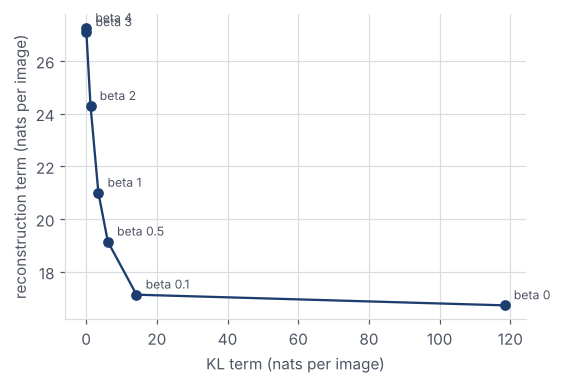

In [6]:
fig, ax = plt.subplots(figsize=(5.4, 3.6))
rec = [np.mean([a for a, _, _ in results[b]]) for b in betas]
kl = [np.mean([k for _, k, _ in results[b]]) for b in betas]
ax.plot(kl, rec, "o-", color=NAVY)
for b, x, y in zip(betas, kl, rec):
    ax.annotate(f"beta {b:g}", (x, y), textcoords="offset points", xytext=(6, 4), fontsize=8, color=BODY)
ax.set_xlabel("KL term (nats per image)"); ax.set_ylabel("reconstruction term (nats per image)")
plt.show()

Moving along the curve trades one term for the other. A small $\beta$ buys a lot of reconstruction at the price of a large KL, which means the encoder's
distribution sits far from the prior, so samples from the prior will not look like the data. At $\beta = 0$ the objective has no KL term at all, and
the model is an autoencoder with noise in the middle. Past a certain $\beta$ the KL term drops to zero. The next section is about that.

## 2. Posterior collapse

When the KL term reaches zero, $q(z|x)$ equals the prior for every image. The code carries no information about the input, and the decoder has
nothing to work from except what is true of all digits on average. We look at what such a model reconstructs.

collapsed model (beta = 4)
  KL per image                         : 0.0008
  posterior mean, spread across images : [0.007 0.016 0.016 0.016 0.011 0.01  0.016 0.017]
  posterior variance, average          : [1.    1.001 1.003 0.999 0.999 1.    0.998 0.999]
  distance of its outputs from the average training image (MSE): 6e-05


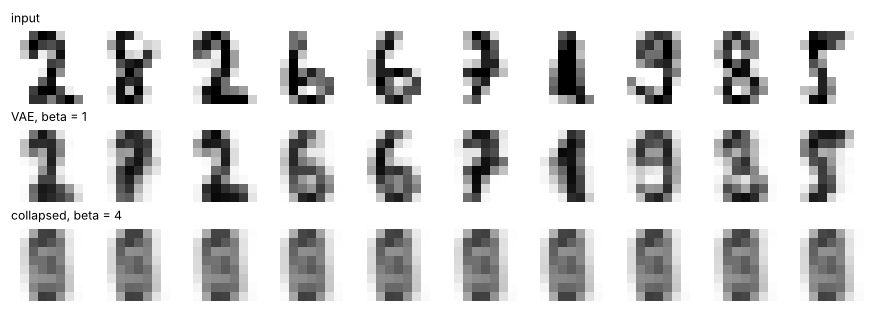

In [7]:
v_col = VAE(d_latent=8); train_vae(v_col, Xtr, epochs=200, beta=4.0, seed=0)
v_ok = VAE(d_latent=8); train_vae(v_ok, Xtr, epochs=200, beta=1.0, seed=0)
mean_image = Xtr.mean(0)
with torch.no_grad():
    rec_col = torch.sigmoid(v_col.decode(v_col.reparameterize(*v_col.encode(Xte[:10]))))
    rec_ok = torch.sigmoid(v_ok.decode(v_ok.reparameterize(*v_ok.encode(Xte[:10]))))
    mu_col, lv_col = v_col.encode(Xte)
print("collapsed model (beta = 4)")
print("  KL per image                         :", round(evaluate_terms(v_col, Xte)[1], 4))
print("  posterior mean, spread across images :", np.round(mu_col.std(0).numpy(), 3))
print("  posterior variance, average          :", np.round(torch.exp(lv_col).mean(0).numpy(), 3))
d = ((rec_col - mean_image) ** 2).mean().item()
print("  distance of its outputs from the average training image (MSE):", round(d, 5))
fig, axes = plt.subplots(3, 10, figsize=(10, 3.3))
for j in range(10):
    for i, (img, name) in enumerate([(Xte[j], "input"), (rec_ok[j], "VAE, beta = 1"), (rec_col[j], "collapsed, beta = 4")]):
        axes[i, j].imshow(img.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(name, fontsize=8, loc="left")
plt.show()

Three signs of collapse are visible. The KL term is zero. The posterior mean no longer varies from one image to the next, and the posterior variance is 1, the prior's
variance. And every reconstruction is the same blurry picture, which is close to the average training image. The model has decided that
saying nothing about the input is cheaper than paying the KL cost to say something. Reconstruction error alone would have shown a big number but
would not have told you why. The KL term and the count of active units do.

## 3. Which latent dimensions are used

Even a healthy VAE often leaves some latent dimensions unused. An unused dimension has a posterior equal to the prior, so it contributes zero KL.
The per-dimension KL below shows which of the eight dimensions the $\beta = 1$ model uses.

KL per latent dimension, beta = 1 : [0.    0.368 0.945 0.518 0.    0.78  0.828 0.   ]
total                              : 3.439
active units (variance of posterior mean > 0.01): 5


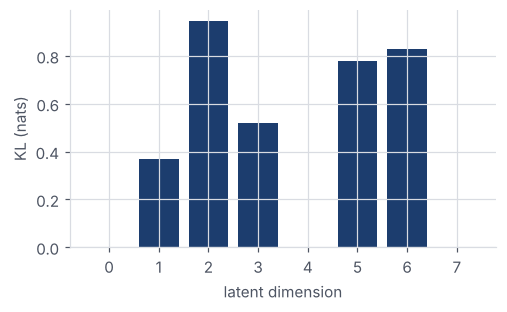

In [8]:
with torch.no_grad():
    mu, lv = v_ok.encode(Xte)
    per_dim = 0.5 * (mu ** 2 + torch.exp(lv) - 1 - lv).mean(0)
print("KL per latent dimension, beta = 1 :", np.round(per_dim.numpy(), 3))
print("total                              :", round(per_dim.sum().item(), 3))
print("active units (variance of posterior mean > 0.01):", active_units(v_ok, Xte))
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(range(8), per_dim.numpy(), color=NAVY); ax.set_xlabel("latent dimension"); ax.set_ylabel("KL (nats)")
plt.show()

The model uses only some of its dimensions. The rest sit at the prior. That is the regularizer at work: a dimension is only worth using if the reduction in
reconstruction error pays for its KL. It also means that the size of the latent space you choose is an upper bound, not the amount of structure the model keeps.

## 4. Does annealing rescue a collapsed model?

A common remedy is KL annealing: start with $\beta = 0$ and raise it to its final value over the first epochs, so the decoder learns to use the code
before the KL cost is applied. We try it at $\beta = 2$ and $\beta = 4$, with three seeds each, and compare the final KL and the number of active units
with the same runs without annealing.

In [9]:
print("beta  anneal epochs   final KL (3 seeds)       active units (3 seeds)")
for beta in (2.0, 4.0):
    for ann in (0, 100):
        kls, acts = [], []
        for seed in range(3):
            v = VAE(d_latent=8); train_vae(v, Xtr, epochs=200, beta=beta, anneal_epochs=ann, seed=seed)
            kls.append(round(evaluate_terms(v, Xte)[1], 2)); acts.append(active_units(v, Xte))
        print(f"{beta:4.1f}  {ann:12d}   {str(kls):24s} {acts}")

beta  anneal epochs   final KL (3 seeds)       active units (3 seeds)


 2.0             0   [1.26, 1.25, 1.22]       [5, 3, 4]


 2.0           100   [1.3, 1.33, 1.39]        [4, 4, 5]


 4.0             0   [0.0, 0.0, 0.0]          [0, 0, 0]


 4.0           100   [0.0, 0.0, 0.0]          [0, 0, 0]


Annealing made no real difference here. At $\beta = 4$ the model collapses either way, and at $\beta = 2$ the two runs end up in the same place. Annealing helps when collapse is
a training accident: a decoder that is strong enough to model the data without the code gets there before the encoder has learned anything, and
never looks back. Here the cause is different. The objective itself is minimized at a collapsed solution when $\beta$ is large, so no schedule can rescue it.
When a model collapses, check the weight on the KL term and the strength of the decoder before reaching for a schedule.

## What to take away

- $\beta$ sets a trade-off between reconstruction and closeness to the prior. $\beta = 1$ is the ELBO; other values are a design choice.
- A collapsed VAE has KL near zero, an encoder that ignores the input, and decoder outputs that all look like the average image. Look at the KL term and
  the active units, not only the reconstruction error.
- The latent size is an upper bound. The model decides how many dimensions are worth using.
- Annealing is a remedy for one cause of collapse, not for all of them.